# 03 Evaluation Design and Baselines
**Real Planet or False Alarm? Classifying Kepler Exoplanet Candidates**  
Keelan O'Dowd (23440916)

This is where I fix how every model will be judged and find out what score is worth beating. The full protocol is in the README.

* **Test set:** the 20% from notebook 01, grouped by star. Not used here.
* **Cross-validation:** 5 grouped folds on the training set, the same folds for every model.
* **Metrics:** PR-AUC first, then F1, precision, recall and ROC-AUC.

Three baselines, matching the three types from week 4:

1. **Dummy**, which ignores the data and just predicts the class rates. The floor.
2. **Planet radius rule**, a tiny tree on `koi_prad` alone, my strongest single feature.
3. **Logistic regression** on all 13 features with default settings, the simplest real model.

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, f1_score,
                             make_scorer, precision_score)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text

from src.data import load_labelled
from src.features import CORE_FEATURES, GROUP
from src.preprocessing import build_preprocessor

RANDOM_STATE = 42
REPORTS = ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

## 1. Training set and folds

In [ ]:
labelled = load_labelled()
train = labelled[labelled["set"] == "train"].reset_index(drop=True)
del labelled

X_train, y_train, groups_train = train[CORE_FEATURES], train["y"], train[GROUP]
prevalence = y_train.mean()

grouped_cv_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                          .split(X_train, y_train, groups=groups_train))
for fitting_indices, validation_indices in grouped_cv_splits:
    assert set(groups_train.iloc[fitting_indices]).isdisjoint(groups_train.iloc[validation_indices])

print(f"Training rows: {len(train):,} | prevalence: {prevalence:.3f} | "
      f"fold sizes: {[len(validation_indices) for _, validation_indices in grouped_cv_splits]}")

c:\Users\keela\programming\machine_learning\Kepler-exoplanet-classification\src\data.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  labelled["y"] = (labelled["koi_disposition"] == "CONFIRMED").astype(int)


Training rows: 6,068 | prevalence: 0.362 | fold sizes: [1214, 1214, 1212, 1214, 1214]


## 2. Models and metrics

The dummy gives every row the same probability, the share of confirmed planets, so its PR-AUC should equal that share. It always predicts "false positive", so its F1, precision and recall are 0 by design. `zero_division=0` just records that as 0 instead of throwing a warning.

In [3]:
models = {
    "Dummy (class rates)": DummyClassifier(strategy="prior"),
    "Planet-radius rule": Pipeline([
        ("pre", build_preprocessor(features=["koi_prad"], scale=False)),
        ("model", DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)),
    ]),
    "Logistic regression": Pipeline([
        ("pre", build_preprocessor()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
}

SCORING = {
    "pr_auc": "average_precision",
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "roc_auc": "roc_auc",
}

## 3. Cross-validated results

In [ ]:
metric_result_rows = []
for model_name, model in models.items():
    cross_validation_results = cross_validate(
        model, X_train, y_train, cv=grouped_cv_splits, scoring=SCORING
    )
    for metric_name in SCORING:
        fold_scores = cross_validation_results[f"test_{metric_name}"]
        metric_result_rows.append({"model": model_name, "metric": metric_name,
                                   "mean": fold_scores.mean(), "std": fold_scores.std()})

results = pd.DataFrame(metric_result_rows)
results.to_csv(REPORTS / "baseline_results.csv", index=False)

table = results.assign(value=results["mean"].map("{:.3f}".format) + " ± " + results["std"].map("{:.3f}".format))
table.pivot(index="model", columns="metric", values="value")[list(SCORING)].loc[list(models)]

metric,pr_auc,f1,precision,recall,roc_auc
model,,,,,
Dummy (class rates),0.362 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Planet-radius rule,0.545 ± 0.009,0.684 ± 0.003,0.551 ± 0.011,0.904 ± 0.042,0.761 ± 0.008
Logistic regression,0.877 ± 0.009,0.835 ± 0.013,0.799 ± 0.019,0.875 ± 0.019,0.937 ± 0.004


* **The setup works.** The dummy lands exactly on 0.362 PR-AUC and 0.5 ROC-AUC, the no skill values.
* **One feature gets you part of the way.** The radius rule lifts PR-AUC to 0.545. It catches 90% of planets, but only 55% of what it flags is real, because it basically calls anything planet sized a planet.
* **All 13 features do much better.** Logistic regression reaches 0.877 PR-AUC and 0.937 ROC-AUC. The gap over the rule is about 0.33, against a fold to fold spread of about 0.01, so it's clearly real.
* **At the default cut-off** it finds 87.5% of real planets, and about 4 in 5 of the KOIs it flags are genuine. The other 1 in 5 would be wasted telescope time.

So the number to beat in Milestone 3 is 0.877, not the dummy.

## 4. What did the radius rule learn?

In [ ]:
radius_rule_model = models["Planet-radius rule"].fit(X_train, y_train)
radius_rule_tree = radius_rule_model.named_steps["model"]
transformed_feature_names = list(radius_rule_model.named_steps["pre"].get_feature_names_out())
print(export_text(radius_rule_tree, feature_names=transformed_feature_names))

for feature_index, split_threshold in zip(radius_rule_tree.tree_.feature,
                                          radius_rule_tree.tree_.threshold):
    if feature_index >= 0 and transformed_feature_names[feature_index] == "koi_prad":
        print(f"Cut-off: koi_prad <= {np.expm1(split_threshold):.2f} Earth radii")

|--- koi_prad <= 2.68
|   |--- koi_prad <= 0.76
|   |   |--- class: 0
|   |--- koi_prad >  0.76
|   |   |--- class: 1
|--- koi_prad >  2.68
|   |--- koi_prad <= 2.95
|   |   |--- class: 0
|   |--- koi_prad >  2.95
|   |   |--- class: 0

Cut-off: koi_prad <= 13.62 Earth radii
Cut-off: koi_prad <= 1.13 Earth radii
Cut-off: koi_prad <= 18.07 Earth radii


The tree splits on the logged radius, so I convert the cut-offs back to Earth radii.

In plain words the rule is: **call it a planet if the radius is between 1.13 and 13.62 Earth radii, otherwise call it a false positive.** The upper limit sits just above Jupiter, which is about 11.2 Earth radii, so anything bigger gets treated as a star. That lines up with notebook 01, where almost nothing over 30 Earth radii was confirmed. The lower limit catches tiny signals, which are harder to confirm and more often false alarms. The third split at 18.07 predicts false positive on both sides, so it doesn't change anything.

## 5. PR curves and confusion matrices

Every row here is predicted by a model that never saw it during training. The curves pool all five folds, so they can differ slightly from the table.

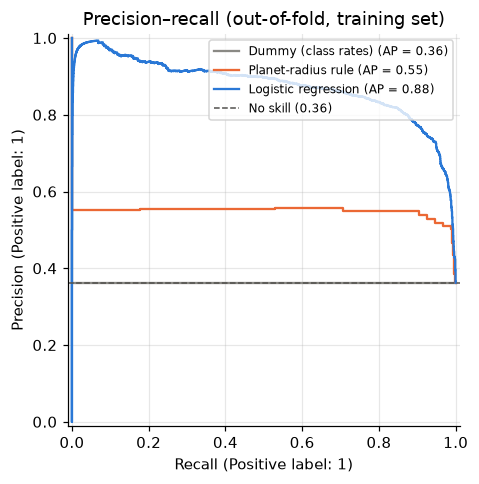

In [ ]:
out_of_fold_probabilities = {
    model_name: cross_val_predict(model, X_train, y_train, cv=grouped_cv_splits,
                                  method="predict_proba")[:, 1]
    for model_name, model in models.items()
}
model_colors = {"Dummy (class rates)": "#8a8984", "Planet-radius rule": "#eb6834",
                "Logistic regression": "#2a78d6"}

fig, ax = plt.subplots(figsize=(6, 4.5))
for model_name, predicted_probabilities in out_of_fold_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_train, predicted_probabilities, name=model_name, ax=ax,
                                           curve_kwargs={"color": model_colors[model_name]})
ax.axhline(prevalence, color="#52514e", ls="--", lw=1, label=f"No skill ({prevalence:.2f})")
ax.set_title("Precision vs recall, out of fold on the training set")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_pr_curves.png", bbox_inches="tight")

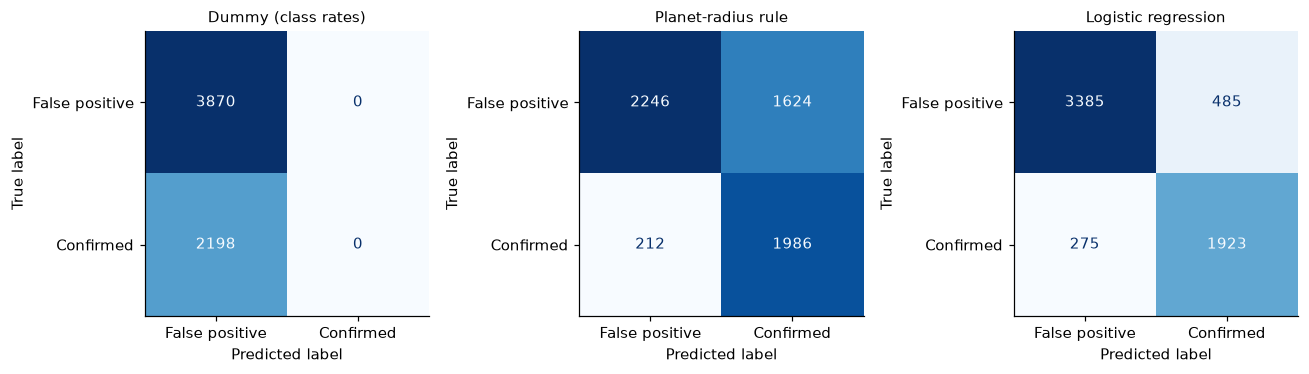

In [ ]:
fig, axes = plt.subplots(1, len(models), figsize=(12, 3.6))
for ax, (model_name, predicted_probabilities) in zip(axes, out_of_fold_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_train, (predicted_probabilities >= 0.5).astype(int),
        display_labels=["False positive", "Confirmed"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(model_name, fontsize=10)
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_confusion_matrices.png", bbox_inches="tight")

* **Curves.** Logistic regression stays around 0.9 precision up to about 60% recall and above 0.8 until about 85%. The KOIs it ranks highest are very reliable, which is exactly what you want when choosing what to follow up. The rule is flat at about 0.55 because it can only give three different scores.
* **Confusion matrices.** Logistic regression misses 275 of 2,198 real planets and raises 485 false alarms out of 3,870 false positives, 12.5% each way. The rule misses slightly fewer planets, 212, but raises 1,624 false alarms, more than three times as many. The dummy misses every planet.
* **Which mistake matters more?** A missed planet may never get looked at again, while a false alarm costs telescope time. Right now the two error rates are balanced, and I can move the cut-off later depending on which cost matters more.

## 6. Does grouping by star matter?

Same model, scored with random folds where a star's KOIs can land on both sides, and with the grouped folds I use everywhere else.

In [ ]:
logistic_regression_model = models["Logistic regression"]
random_fold_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pd.DataFrame({
    "random folds (ignore stars)": cross_val_score(logistic_regression_model, X_train, y_train,
                                                   cv=random_fold_splitter, scoring="average_precision"),
    "grouped by star": cross_val_score(logistic_regression_model, X_train, y_train,
                                        cv=grouped_cv_splits, scoring="average_precision"),
}).agg(["mean", "std"]).T.round(3)

,mean,std
random folds (ignore stars),0.879,0.018
grouped by star,0.877,0.010


For logistic regression it makes almost no difference, 0.879 random against 0.877 grouped, which is well inside the noise. Most training stars only have one KOI, 6,068 KOIs across 5,306 stars, and a linear model can't really memorise individual stars anyway.

I'm still keeping the grouping. It matches real use, where new candidates come from stars the model has never seen, and flexible models like k-NN and random forests can memorise a star's exact values. I'll check those in Milestone 3.

## Summary

| Model | PR-AUC, 5 grouped folds |
|---|---|
| Dummy | 0.362 |
| Planet radius rule | 0.545 ± 0.009 |
| **Logistic regression** | **0.877 ± 0.009** |

Logistic regression is the bar for Milestone 3. A new model needs to beat 0.877 by clearly more than the fold spread of about 0.01 to count as an improvement. The dummy landing exactly on the no skill values, the shared grouped folds and the untouched test set all show the evaluation is working as intended.

**One caveat:** these scores may be a little optimistic. About 14% of training rows use older stellar data and are almost all false positives, as shown in notebook 01, section 8C. I'll measure that in Milestone 3.